# 04 — One-stage anchor-free detector: YOLO26n

Rubric item: *One-stage anchor-free*. Numbers are read from `results/` (written by `scripts/05_evaluate.py` and `07_failure_cases.py`); nothing here is retyped by hand.

In [1]:
import json, sys
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import CLASS_NAMES

def show(name, width=900, folder="images"):
    display(Image(filename=str(ROOT / folder / name), width=width))

def table(rows, header):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)] + ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

def load(path):
    p = ROOT / path
    return json.loads(p.read_text()) if p.is_file() else None

f3 = lambda v: "n/a" if v is None else f"{v:.3f}"

## Starting point: the earlier Colab run


- **Model:** Ultralytics YOLO26n, COCO-pretrained, fine-tuned for the 8 classes.
- **Data and training (Colab T4):** the same 4,868-frame sample converted to YOLO format with ignored regions dropped (the format has no ignore flag), image size 640, batch 16, patience 3, a 45-minute limit. Best epoch 4 of a run stopped at epoch 7.
- **Scoring:** Ultralytics' own validation uses the converted labels, so the scores below are recomputed with the COCO evaluator on the original annotations.

## Results of the best run of this family on the validation split

All 2,846 frames of the 7 validation clips, COCO metrics with ignored regions respected, up to 500 detections per frame. Speed is the time of one forward pass per frame at batch size 1 on this Mac's GPU (MPS), the same for every model, so it is comparable across models but not with the earlier T4 timings.

In [2]:
r = load("results/eval/yolo26n-hires960.json")
table([[f3(r["AP"]), f3(r["AP50"]), f3(r["AP75"]), f3(r["AP_small"]), f3(r["AP_medium"]), f3(r["AP_large"]), f'{r["ms_per_frame"]:.0f}']],
      ["mAP", "AP50", "AP75", "AP small", "AP medium", "AP large", "ms per frame"])
table([[c, f3(v)] for c, v in r["per_class"].items()], ["class", "AP"])

| mAP | AP50 | AP75 | AP small | AP medium | AP large | ms per frame |
|---|---|---|---|---|---|---|
| 0.162 | 0.308 | 0.151 | 0.062 | 0.136 | 0.332 | 12 |

| class | AP |
|---|---|
| person | 0.243 |
| bicycle | 0.074 |
| car | 0.361 |
| van | 0.127 |
| truck | 0.068 |
| tricycle | 0.162 |
| bus | 0.165 |
| motor | 0.100 |

### By clip

In [3]:
r = load("results/eval/yolo26n-hires960.json")
table([[c, v["frames"], f3(v["AP"]), f3(v["AP50"]), f3(v["AP_small"])] for c, v in sorted(r["per_clip"].items(), key=lambda kv: -(kv[1]["AP"] or 0))],
      ["validation clip", "frames", "AP", "AP50", "AP small"])

| validation clip | frames | AP | AP50 | AP small |
|---|---|---|---|---|
| uav0000137_00458_v | 233 | 0.239 | 0.443 | 0.001 |
| uav0000086_00000_v | 464 | 0.216 | 0.451 | 0.181 |
| uav0000305_00000_v | 184 | 0.201 | 0.298 | 0.029 |
| uav0000339_00001_v | 275 | 0.195 | 0.370 | 0.052 |
| uav0000117_02622_v | 349 | 0.177 | 0.374 | 0.009 |
| uav0000182_00000_v | 363 | 0.108 | 0.245 | 0.072 |
| uav0000268_05773_v | 978 | 0.071 | 0.095 | 0.000 |

## Failure cases

Detections with score >= 0.3 matched to ground truth at IoU 0.5 (detections inside ignored regions dropped). A box found with the wrong class counts as a miss. Green = found, red = missed, blue = false positive.

In [4]:
f = load("results/failures/yolo26n-hires960.json")
table([[k, f"{v:.0%}"] for k, v in f["recall_by_size"].items()], ["object size", "share found"])
table([[k, f"{v:.0%}"] for k, v in f["recall_by_class"].items()], ["class", "share found"])
table([[p["truth"], p["predicted"], p["count"]] for p in f["top_class_confusions"]], ["true class", "predicted as", "count"])
table([[c, v["frames"], f'{v["recall"]:.0%}', v["false_positives_per_frame"]] for c, v in sorted(f["clips"].items(), key=lambda kv: kv[1]["recall"])], ["clip", "frames", "share found", "false positives per frame"])

| object size | share found |
|---|---|
| small | 21% |
| medium | 40% |
| large | 66% |

| class | share found |
|---|---|
| person | 44% |
| motor | 25% |
| bicycle | 6% |
| car | 53% |
| tricycle | 21% |
| van | 12% |
| truck | 11% |
| bus | 21% |

| true class | predicted as | count |
|---|---|---|
| van | car | 2755 |
| bicycle | motor | 1455 |
| bicycle | person | 798 |
| person | motor | 616 |
| motor | person | 504 |
| tricycle | car | 317 |
| car | van | 195 |
| bus | car | 160 |

| clip | frames | share found | false positives per frame |
|---|---|---|---|
| uav0000268_05773_v | 978 | 12% | 1.0 |
| uav0000182_00000_v | 363 | 29% | 6.1 |
| uav0000117_02622_v | 349 | 30% | 2.8 |
| uav0000339_00001_v | 275 | 40% | 4.0 |
| uav0000137_00458_v | 233 | 42% | 6.1 |
| uav0000086_00000_v | 464 | 60% | 7.7 |
| uav0000305_00000_v | 184 | 62% | 9.3 |

01_uav0000137_00458_v_0142_missed82_fp15.jpg


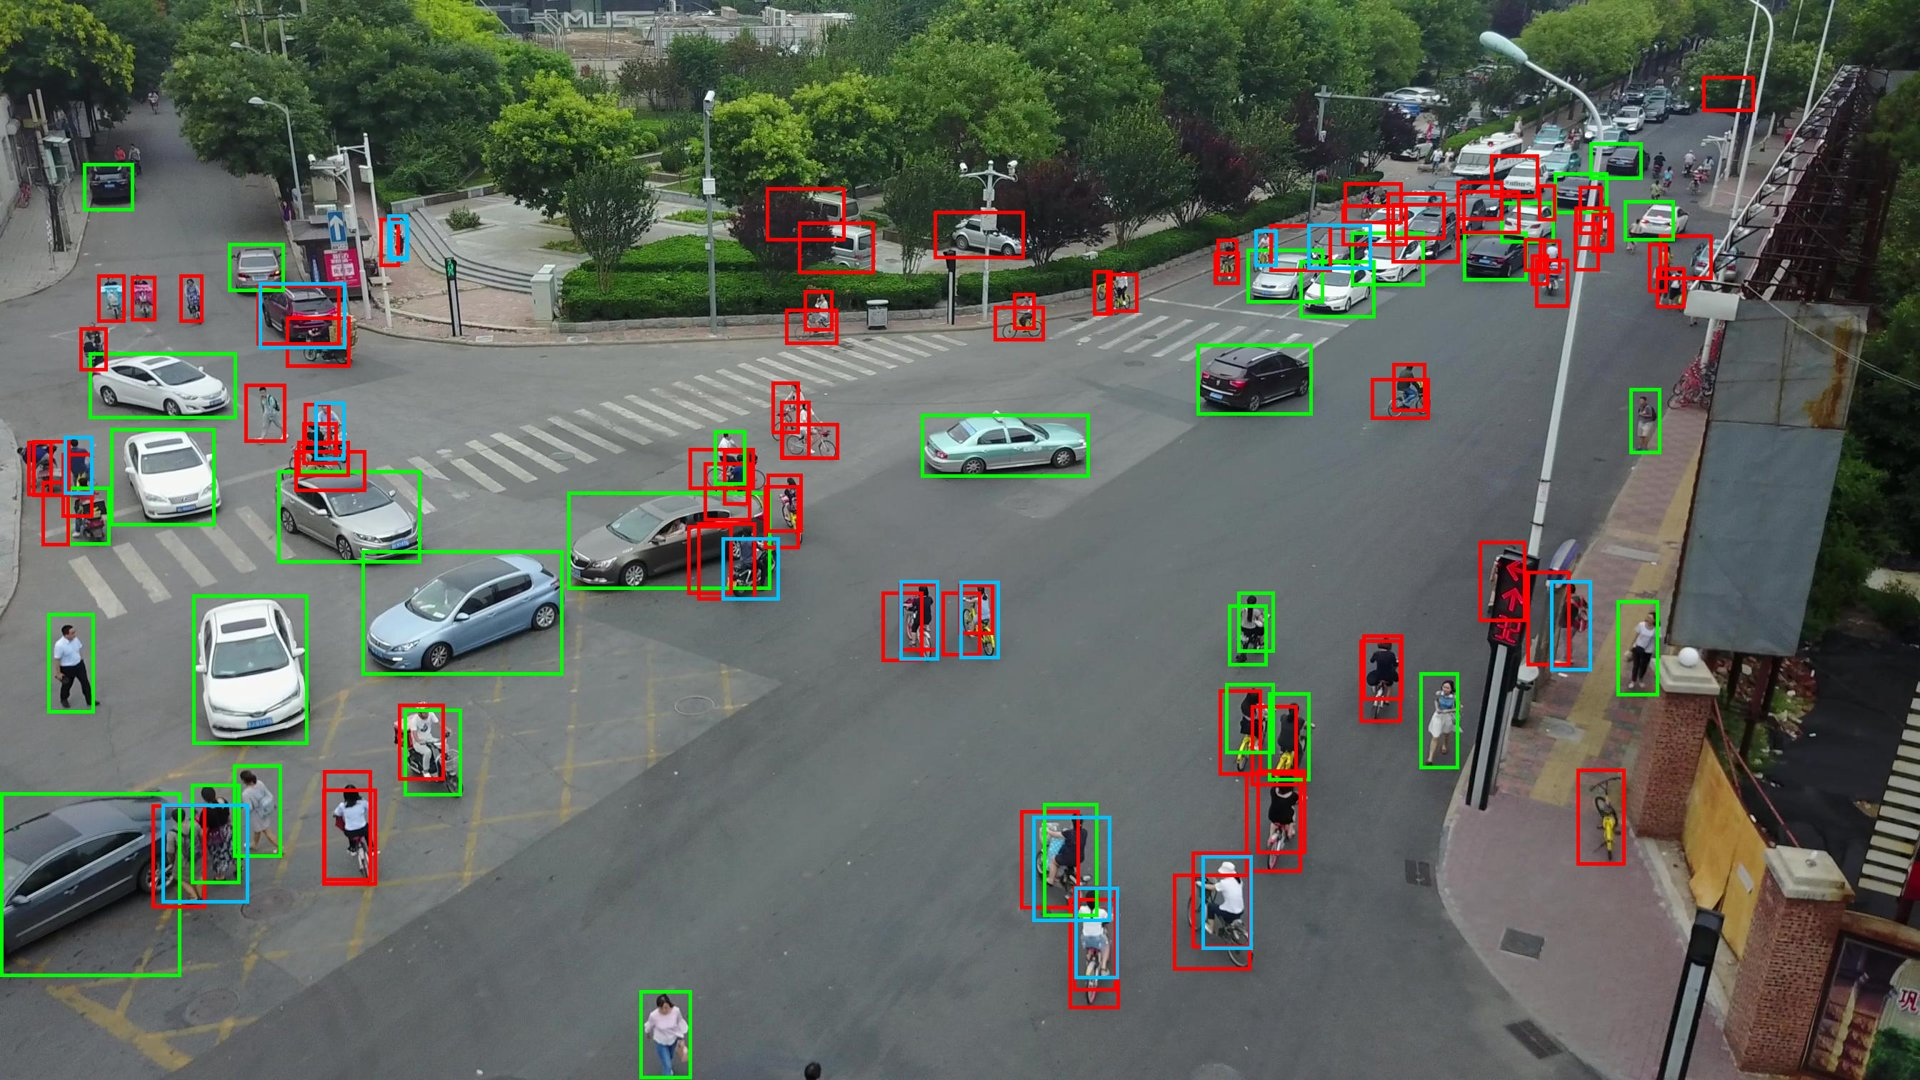

02_uav0000137_00458_v_0143_missed80_fp13.jpg


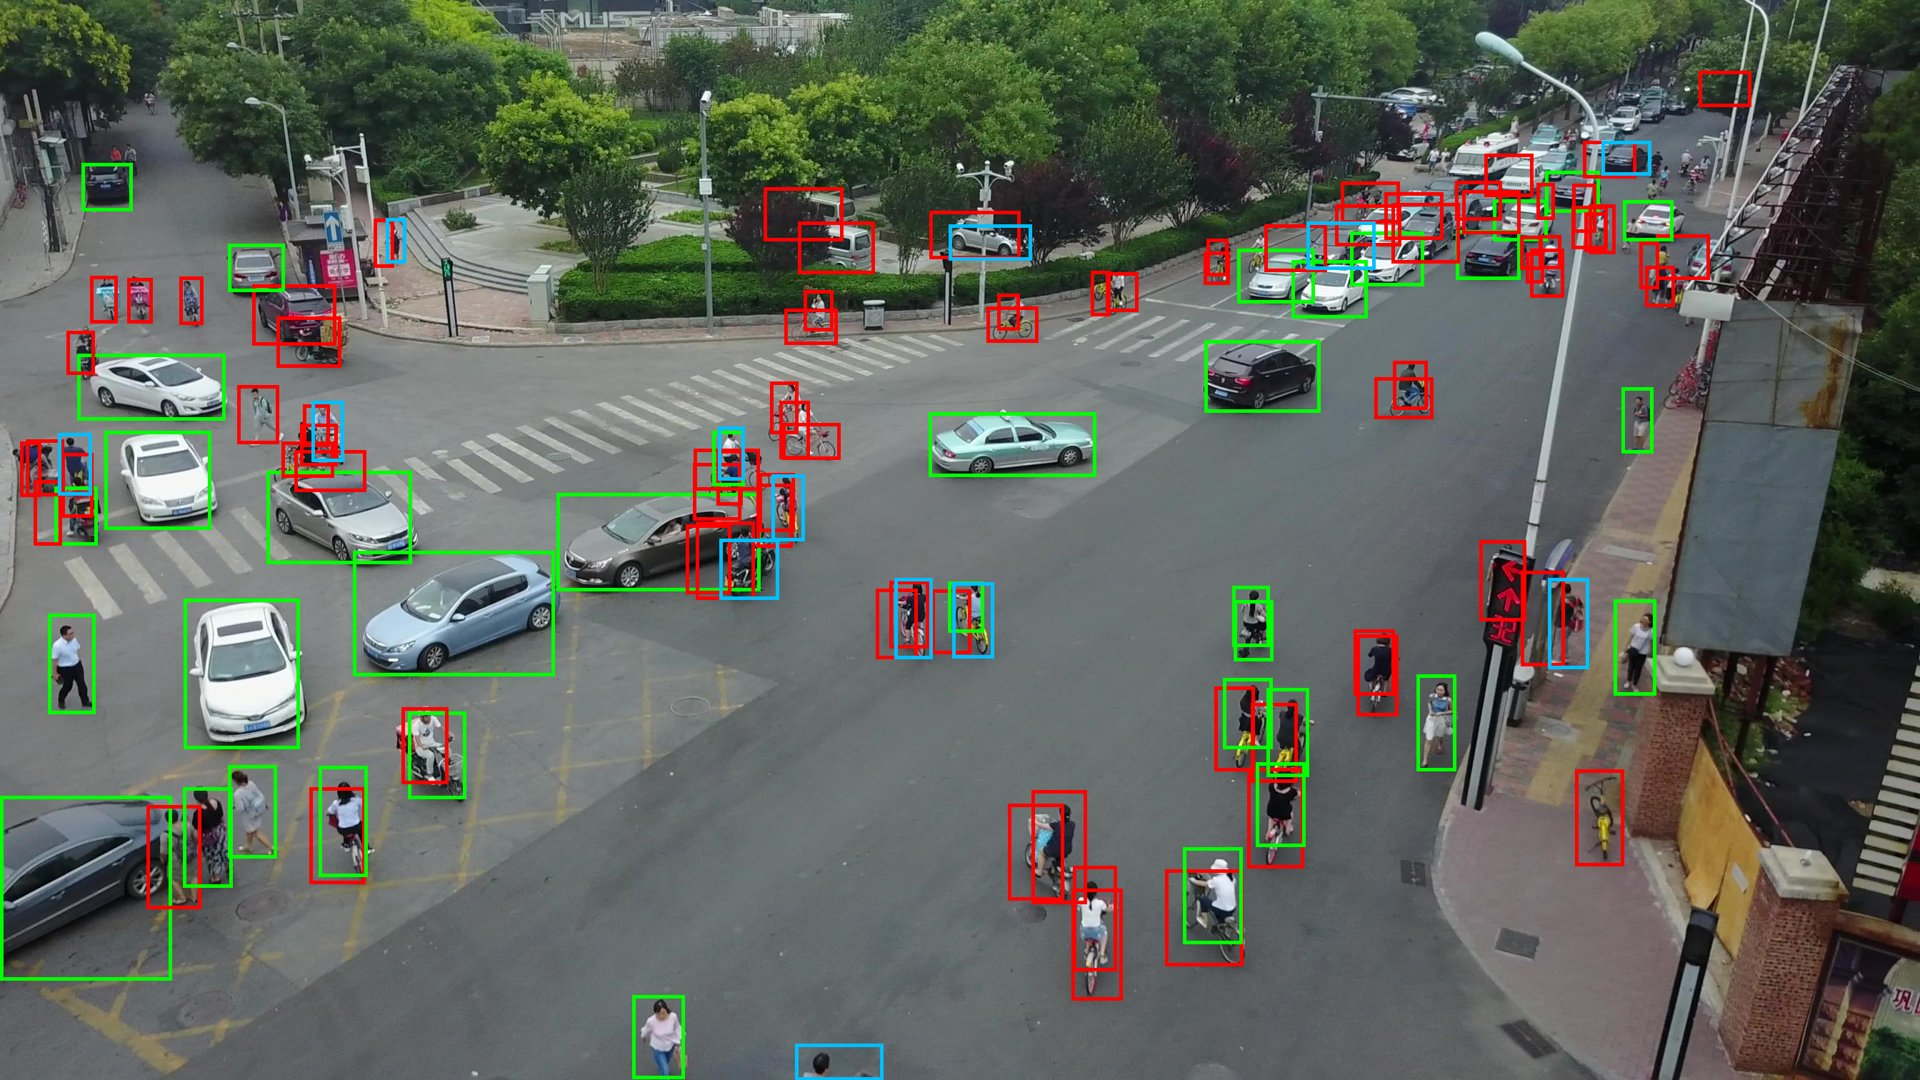

03_uav0000117_02622_v_0304_missed83_fp6.jpg


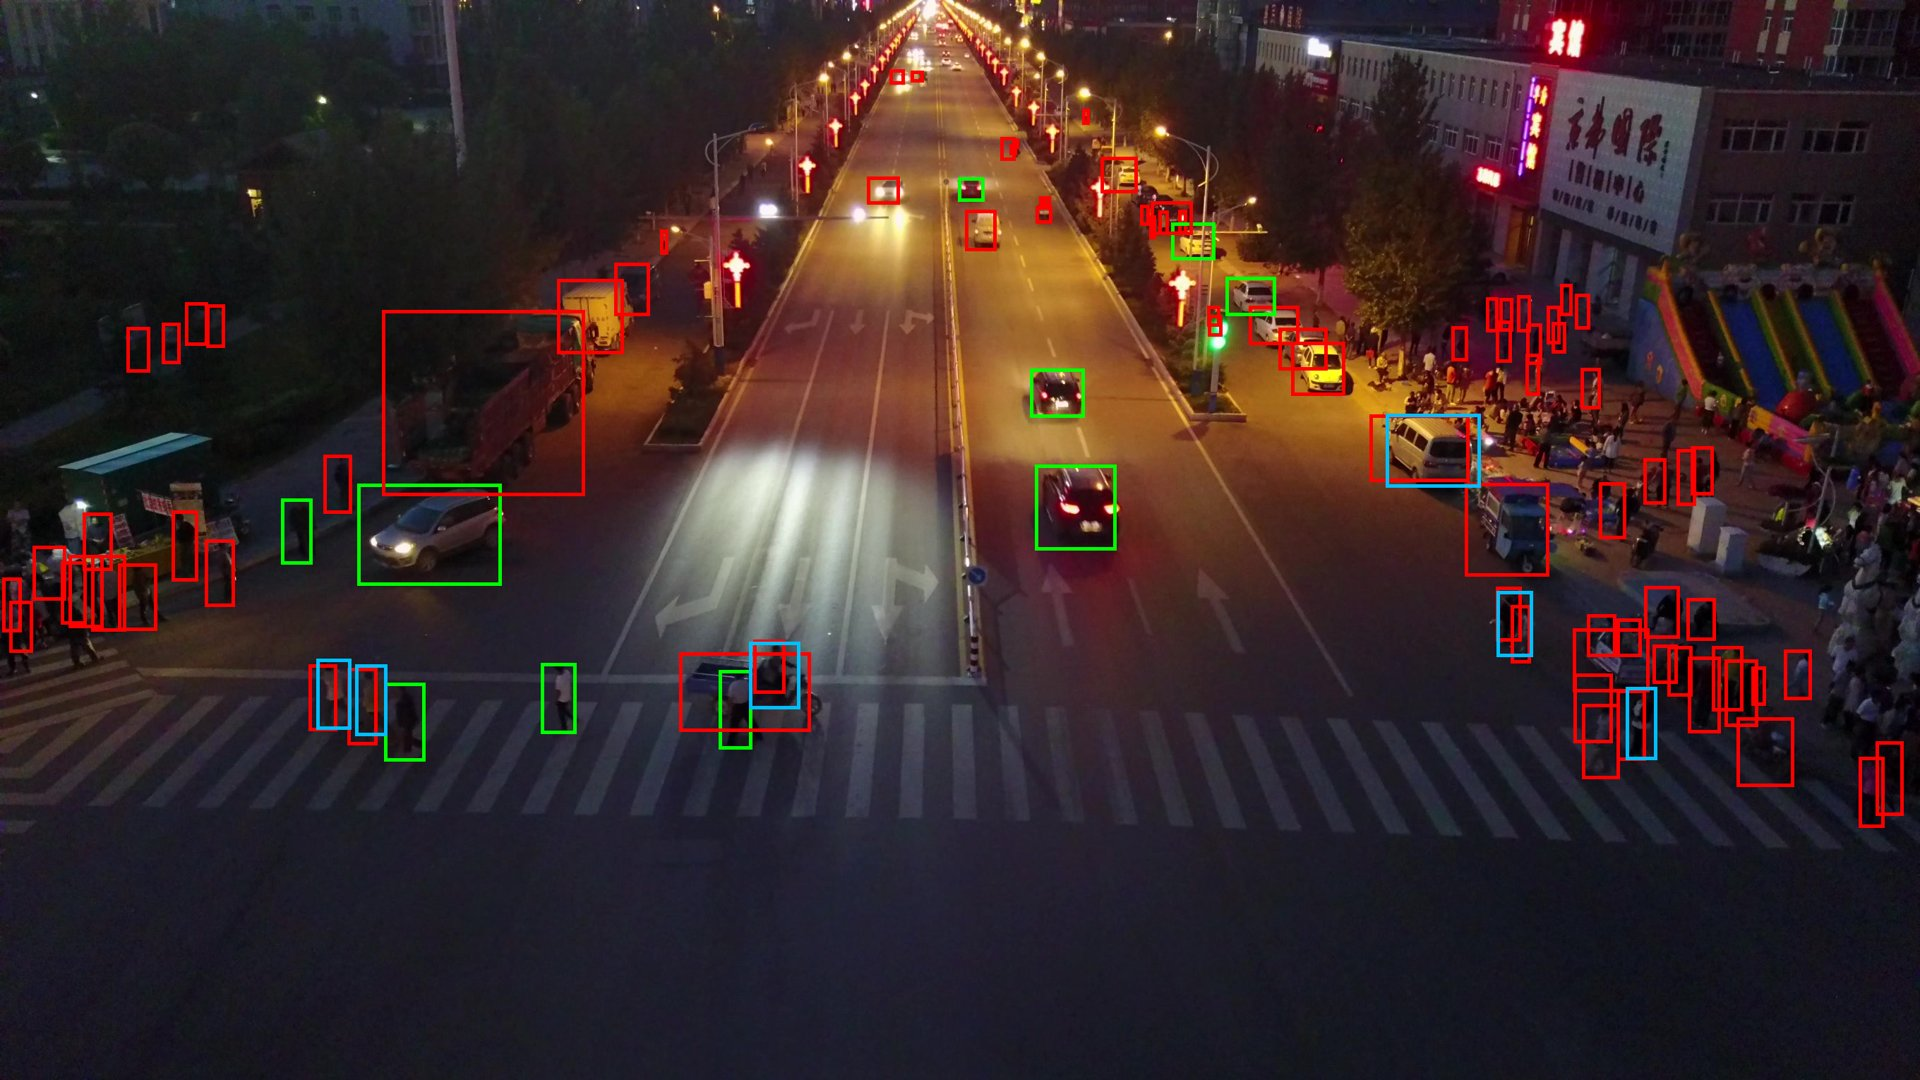

In [5]:
for path in sorted((ROOT / "runs" / "failures" / "yolo26n-hires960").glob("*.jpg"))[:3]:
    print(path.name)
    display(Image(filename=str(path), width=900))

## Tuning experiments

Every run starts from the same COCO weights, trains on the same 4,868 frames for the same short budget on one machine (a Mac Mini, Apple GPU), and changes one thing against the baseline run of its family (`EXPERIMENTS.md` has the protocol and the commands):

- `yolo26n-base`: 640 px, 15 minutes
- `yolo26n-hires960`: input size 640 → 960 px
- `yolo26n-box10`: box-loss weight 7.5 → 10 (the loss change)

The table lists every run of this family scored with `scripts/05_evaluate.py` on all validation frames.

In [6]:
rows = []
for path in sorted((ROOT / "results" / "eval").glob("yolo*.json")):
    r = json.loads(path.read_text())
    rows.append([r["name"], f3(r["AP"]), f3(r["AP50"]), f3(r["AP_small"]), f'{r["ms_per_frame"]:.0f}'])
table(rows, ["run", "AP", "AP50", "AP small", "ms per frame"]) if rows else print("no tuned runs evaluated yet")

| run | AP | AP50 | AP small | ms per frame |
|---|---|---|---|---|
| yolo26n-base | 0.128 | 0.243 | 0.040 | 13 |
| yolo26n-box10 | 0.108 | 0.218 | 0.038 | 13 |
| yolo26n-hires960 | 0.162 | 0.308 | 0.062 | 12 |